Program: AI / ML / Deep Learning NAVTTC

Name: Yusra Nazish

Week 4, Day 1
Topic: Pandas

Assignment 46: Data Analysis with Pandas
Assignment 47: Data Cleaning with Pandas
Assignment 48: Data Correlation with Pandas

References:
W3Schools, Pandas Analyzing DataFrames
W3Schools, Pandas Cleaning Data
W3Schools, Pandas Correlations

Import Libraries

In [2]:
import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")
print("Pandas version:", pd.__version__)

Pandas version: 3.0.6


Dataset Used in All Three Assignments

The W3Schools exercises use a fitness dataset with the columns Duration, Date, Pulse, Maxpulse and Calories. The data is typed directly into the notebook so that no file needs to be downloaded.

Duration: length of the workout in minutes
Date: date of the workout
Pulse: average heart rate during the workout
Maxpulse: maximum heart rate during the workout
Calories: calories burned during the workout

The data is intentionally untidy. It contains empty cells, a wrong date format, a wrong value and duplicate rows, which are fixed in Assignment 47.

In [3]:
raw_data = """Duration,Date,Pulse,Maxpulse,Calories
60,2020/12/01,110,130,409.1
60,2020/12/02,117,145,479.0
60,2020/12/03,103,135,340.0
45,2020/12/04,109,175,282.4
45,2020/12/05,117,148,406.0
60,2020/12/06,102,127,300.0
60,2020/12/07,110,136,374.0
450,2020/12/08,104,134,253.3
30,2020/12/09,109,133,195.1
60,2020/12/10,98,124,269.0
60,2020/12/11,103,147,329.3
60,2020/12/12,100,120,250.7
60,2020/12/12,100,120,250.7
60,2020/12/14,106,128,345.3
60,2020/12/15,104,132,379.3
60,2020/12/16,98,123,275.0
60,2020/12/17,98,120,215.2
60,2020/12/18,100,120,300.0
45,2020/12/19,90,112,
60,2020/12/20,103,123,323.0
45,2020/12/21,97,125,243.0
60,2020/12/22,108,131,364.2
45,,100,119,282.0
60,2020/12/24,130,101,300.0
60,2020/12/25,105,132,246.0
60,2020/12/26,102,126,334.5
60,20201226,100,120,250.0
60,2020/12/28,92,118,241.0
60,2020/12/29,103,132,
60,2020/12/30,100,132,280.0
60,2020/12/31,102,129,380.3
60,2021/01/01,92,115,243.0
"""

df_raw = pd.read_csv(io.StringIO(raw_data))
df_raw.to_csv("fitness_data.csv", index=False)
print("Dataset created and saved as fitness_data.csv")

Dataset created and saved as fitness_data.csv


Assignment 46
Data Analysis with Pandas

Reference: W3Schools, Pandas Analyzing DataFrames

Objective: To explore a DataFrame and understand its structure, contents and basic statistics using Pandas.

Load the Data

In [4]:
df = pd.read_csv("fitness_data.csv")
df

,Duration,Date,Pulse,Maxpulse,Calories
0,60,2020/12/01,110,130,409.1
1,60,2020/12/02,117,145,479.0
2,60,2020/12/03,103,135,340.0
3,45,2020/12/04,109,175,282.4
4,45,2020/12/05,117,148,406.0
5,60,2020/12/06,102,127,300.0
6,60,2020/12/07,110,136,374.0
7,450,2020/12/08,104,134,253.3
8,30,2020/12/09,109,133,195.1
9,60,2020/12/10,98,124,269.0


Viewing the Data with head()

The head() method shows the first rows of the DataFrame. By default it shows 5 rows, and a number can be passed to show more or fewer.

In [5]:
print("First 5 rows:")
print(df.head())
print()
print("First 10 rows:")
print(df.head(10))

First 5 rows:
   Duration        Date  Pulse  Maxpulse  Calories
0        60  2020/12/01    110       130     409.1
1        60  2020/12/02    117       145     479.0
2        60  2020/12/03    103       135     340.0
3        45  2020/12/04    109       175     282.4
4        45  2020/12/05    117       148     406.0

First 10 rows:
   Duration        Date  Pulse  Maxpulse  Calories
0        60  2020/12/01    110       130     409.1
1        60  2020/12/02    117       145     479.0
2        60  2020/12/03    103       135     340.0
3        45  2020/12/04    109       175     282.4
4        45  2020/12/05    117       148     406.0
5        60  2020/12/06    102       127     300.0
6        60  2020/12/07    110       136     374.0
7       450  2020/12/08    104       134     253.3
8        30  2020/12/09    109       133     195.1
9        60  2020/12/10     98       124     269.0


Viewing the Data with tail()

The tail() method shows the last rows of the DataFrame. By default it also shows 5 rows.

In [6]:
print("Last 5 rows:")
print(df.tail())

Last 5 rows:
    Duration        Date  Pulse  Maxpulse  Calories
27        60  2020/12/28     92       118     241.0
28        60  2020/12/29    103       132       NaN
29        60  2020/12/30    100       132     280.0
30        60  2020/12/31    102       129     380.3
31        60  2021/01/01     92       115     243.0


Shape, Columns and Data Types

shape gives the number of rows and columns, columns gives the column names and dtypes gives the data type of each column.

In [7]:
print("Shape (rows, columns):", df.shape)
print("Number of rows        :", df.shape[0])
print("Number of columns     :", df.shape[1])
print()
print("Column names:", list(df.columns))
print()
print("Data types:")
print(df.dtypes)

Shape (rows, columns): (32, 5)
Number of rows        : 32
Number of columns     : 5

Column names: ['Duration', 'Date', 'Pulse', 'Maxpulse', 'Calories']

Data types:
Duration      int64
Date            str
Pulse         int64
Maxpulse      int64
Calories    float64
dtype: object


Information About the Data with info()

The info() method gives a short summary: the number of rows, the columns, how many non-null values each column has, the data type of each column and the memory used.

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 32 entries, 0 to 31
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Duration  32 non-null     int64  
 1   Date      31 non-null     str    
 2   Pulse     32 non-null     int64  
 3   Maxpulse  32 non-null     int64  
 4   Calories  30 non-null     float64
dtypes: float64(1), int64(3), str(1)
memory usage: 1.7 KB


Observation: The dataset has 32 rows and 5 columns. The Calories column shows 30 non-null values and the Date column shows 31, so some values are missing. The Date column is stored as text (string) and not as a real date type.

Summary Statistics with describe()

The describe() method gives the count, mean, standard deviation, minimum, quartiles and maximum of every numeric column.

In [9]:
df.describe()

,Duration,Pulse,Maxpulse,Calories
count,32.000000,32.000000,32.000000,30.000000
mean,68.906250,103.500000,128.500000,304.680000
std,69.927778,7.832933,12.998759,66.003779
min,30.000000,90.000000,101.000000,195.100000
25%,60.000000,100.000000,120.000000,250.700000
50%,60.000000,102.500000,127.500000,291.200000
75%,60.000000,106.500000,132.250000,343.975000
max,450.000000,130.000000,175.000000,479.000000


Observation: The mean Duration is much higher than the 75 percent value, and the maximum Duration is 450 while most workouts last 60 minutes or less. This points to an unusual value in the Duration column, which is handled in the cleaning assignment.

Checking for Missing Values

In [10]:
print("Missing values per column:")
print(df.isnull().sum())
print()
print("Total missing values:", df.isnull().sum().sum())

Missing values per column:
Duration    0
Date        1
Pulse       0
Maxpulse    0
Calories    2
dtype: int64

Total missing values: 3


Selecting Columns and Rows

In [11]:
print("Single column (Calories), first 5 values:")
print(df["Calories"].head())
print()
print("Two columns (Duration and Calories), first 5 rows:")
print(df[["Duration", "Calories"]].head())
print()
print("Row at position 3 using iloc:")
print(df.iloc[3])
print()
print("Rows 0 to 4 and the first three columns using iloc:")
print(df.iloc[0:5, 0:3])

Single column (Calories), first 5 values:
0    409.1
1    479.0
2    340.0
3    282.4
4    406.0
Name: Calories, dtype: float64

Two columns (Duration and Calories), first 5 rows:
   Duration  Calories
0        60     409.1
1        60     479.0
2        60     340.0
3        45     282.4
4        45     406.0

Row at position 3 using iloc:
Duration            45
Date        2020/12/04
Pulse              109
Maxpulse           175
Calories         282.4
Name: 3, dtype: object

Rows 0 to 4 and the first three columns using iloc:
   Duration        Date  Pulse
0        60  2020/12/01    110
1        60  2020/12/02    117
2        60  2020/12/03    103
3        45  2020/12/04    109
4        45  2020/12/05    117


Individual Statistics of a Column

In [12]:
print("Mean of Calories   :", round(df["Calories"].mean(), 2))
print("Median of Calories :", df["Calories"].median())
print("Maximum of Calories:", df["Calories"].max())
print("Minimum of Calories:", df["Calories"].min())
print("Std of Calories    :", round(df["Calories"].std(), 2))
print()
print("Most common Duration (mode):", df["Duration"].mode()[0])

Mean of Calories   : 304.68
Median of Calories : 291.2
Maximum of Calories: 479.0
Minimum of Calories: 195.1
Std of Calories    : 66.0

Most common Duration (mode): 60


Counting Values with value_counts()

In [13]:
print("How many times each Duration appears:")
print(df["Duration"].value_counts())
print()
print("Number of unique Pulse values:", df["Pulse"].nunique())

How many times each Duration appears:
Duration
60     25
45      5
450     1
30      1
Name: count, dtype: int64

Number of unique Pulse values: 15


Filtering Rows

A condition inside square brackets returns only the rows where the condition is true.

In [14]:
high_calories = df[df["Calories"] > 350]
print("Workouts that burned more than 350 calories:", len(high_calories))
print(high_calories)

Workouts that burned more than 350 calories: 7
    Duration        Date  Pulse  Maxpulse  Calories
0         60  2020/12/01    110       130     409.1
1         60  2020/12/02    117       145     479.0
4         45  2020/12/05    117       148     406.0
6         60  2020/12/07    110       136     374.0
14        60  2020/12/15    104       132     379.3
21        60  2020/12/22    108       131     364.2
30        60  2020/12/31    102       129     380.3


In [15]:
long_and_intense = df[(df["Duration"] >= 60) & (df["Maxpulse"] > 130)]
print("Workouts of 60 minutes or more with Maxpulse above 130:", len(long_and_intense))
print(long_and_intense[["Duration", "Pulse", "Maxpulse", "Calories"]])

Workouts of 60 minutes or more with Maxpulse above 130: 10
    Duration  Pulse  Maxpulse  Calories
1         60    117       145     479.0
2         60    103       135     340.0
6         60    110       136     374.0
7        450    104       134     253.3
10        60    103       147     329.3
14        60    104       132     379.3
21        60    108       131     364.2
24        60    105       132     246.0
28        60    103       132       NaN
29        60    100       132     280.0


Sorting the Data

In [16]:
print("Top 5 workouts by calories burned:")
print(df.sort_values(by="Calories", ascending=False).head())
print()
print("5 workouts with the lowest Pulse:")
print(df.sort_values(by="Pulse").head())

Top 5 workouts by calories burned:
    Duration        Date  Pulse  Maxpulse  Calories
1         60  2020/12/02    117       145     479.0
0         60  2020/12/01    110       130     409.1
4         45  2020/12/05    117       148     406.0
30        60  2020/12/31    102       129     380.3
14        60  2020/12/15    104       132     379.3

5 workouts with the lowest Pulse:
    Duration        Date  Pulse  Maxpulse  Calories
18        45  2020/12/19     90       112       NaN
27        60  2020/12/28     92       118     241.0
31        60  2021/01/01     92       115     243.0
20        45  2020/12/21     97       125     243.0
15        60  2020/12/16     98       123     275.0


Grouping the Data with groupby()

In [17]:
print("Average values for each Duration:")
print(df.groupby("Duration")[["Pulse", "Maxpulse", "Calories"]].mean().round(2))

Average values for each Duration:
           Pulse  Maxpulse  Calories
Duration                            
30        109.00    133.00    195.10
45        102.60    135.80    303.35
60        103.44    126.64    311.61
450       104.00    134.00    253.30


Visualising the Data

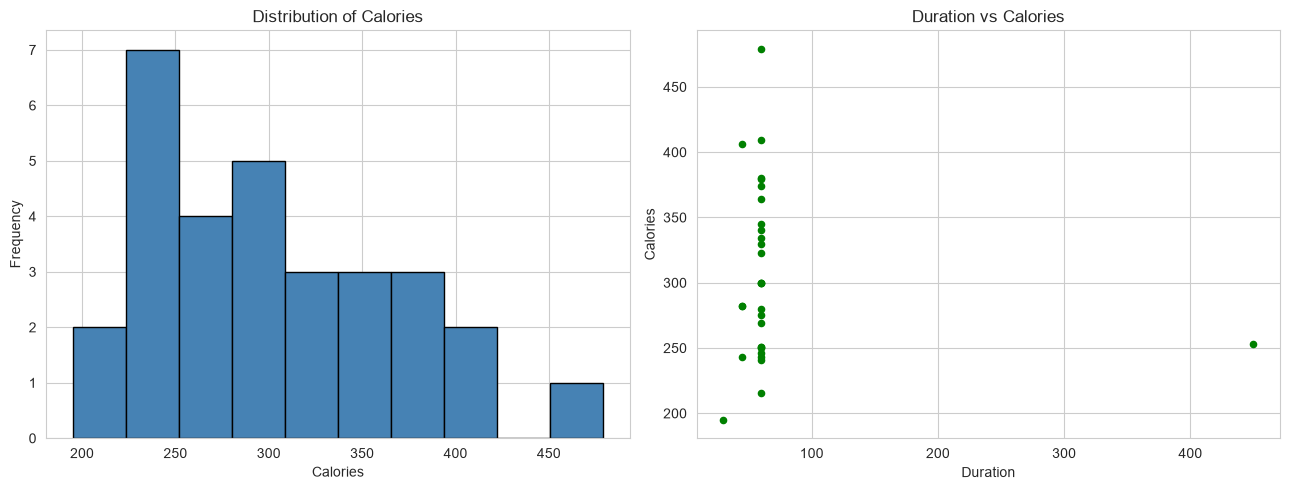

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

df["Calories"].plot(kind="hist", bins=10, ax=axes[0], color="steelblue", edgecolor="black")
axes[0].set_title("Distribution of Calories")
axes[0].set_xlabel("Calories")

df.plot(kind="scatter", x="Duration", y="Calories", ax=axes[1], color="green")
axes[1].set_title("Duration vs Calories")

plt.tight_layout()
plt.show()

Conclusion of Assignment 46

The dataset has 32 rows and 5 columns. Using head(), tail(), shape, info() and describe(), the structure and statistics of the data were examined. The analysis showed that Calories and Date contain missing values, that the Date column is stored as text and that Duration contains an unusually large value of 450. Filtering, sorting and grouping were also used to answer simple questions about the data. These problems are fixed in Assignment 47.

Assignment 47
Data Cleaning with Pandas

Reference: W3Schools, Pandas Cleaning Data

Objective: To clean a messy dataset by handling empty cells, wrong formats, wrong data and duplicates.

Bad data can be empty cells, data in the wrong format, wrong data and duplicates. A fresh copy of the original data is used here so that this assignment can run on its own.

In [19]:
df = pd.read_csv("fitness_data.csv")
print("Shape before cleaning:", df.shape)
df

Shape before cleaning: (32, 5)


,Duration,Date,Pulse,Maxpulse,Calories
0,60,2020/12/01,110,130,409.1
1,60,2020/12/02,117,145,479.0
2,60,2020/12/03,103,135,340.0
3,45,2020/12/04,109,175,282.4
4,45,2020/12/05,117,148,406.0
5,60,2020/12/06,102,127,300.0
6,60,2020/12/07,110,136,374.0
7,450,2020/12/08,104,134,253.3
8,30,2020/12/09,109,133,195.1
9,60,2020/12/10,98,124,269.0


Step 1: Find the Problems

In [20]:
print("Missing values per column:")
print(df.isnull().sum())
print()
print("Duplicated rows:", df.duplicated().sum())
print(df[df.duplicated(keep=False)])
print()
print("Data type of Date column:", df["Date"].dtype)

Missing values per column:
Duration    0
Date        1
Pulse       0
Maxpulse    0
Calories    2
dtype: int64

Duplicated rows: 1
    Duration        Date  Pulse  Maxpulse  Calories
11        60  2020/12/12    100       120     250.7
12        60  2020/12/12    100       120     250.7

Data type of Date column: str


Step 2: Empty Cells

There are two common ways to deal with empty cells. The first is to remove the rows that contain them with dropna(). The second is to fill them with a value using fillna(). Both are shown below on copies of the data so the original is not changed.

Option 1: Remove rows with empty cells using dropna()

In [21]:
df_dropped = df.dropna()
print("Rows before:", len(df))
print("Rows after dropna():", len(df_dropped))

Rows before: 32
Rows after dropna(): 29


Option 2: Replace empty cells using fillna()

Replacing with a fixed value is simple but not always sensible. A better choice for a numeric column is the mean, median or mode of that column. The median is used here because it is not affected by extreme values.

In [22]:
df_fixed_value = df.copy()
df_fixed_value["Calories"] = df_fixed_value["Calories"].fillna(130)
print(df_fixed_value.loc[[18, 28], "Calories"])

18    130.0
28    130.0
Name: Calories, dtype: float64


In [23]:
calories_mean = df["Calories"].mean()
calories_median = df["Calories"].median()
calories_mode = df["Calories"].mode()[0]

print("Mean of Calories  :", round(calories_mean, 2))
print("Median of Calories:", calories_median)
print("Mode of Calories  :", calories_mode)

Mean of Calories  : 304.68
Median of Calories: 291.2
Mode of Calories  : 300.0


In [24]:
df["Calories"] = df["Calories"].fillna(calories_median)

print("Missing values in Calories after filling:", df["Calories"].isnull().sum())
print(df.loc[[18, 28], ["Duration", "Date", "Calories"]])

Missing values in Calories after filling: 0
    Duration        Date  Calories
18        45  2020/12/19     291.2
28        60  2020/12/29     291.2


Observation: The two missing Calories values were filled with the median, which is 291.2. For the Date column, a missing date cannot be guessed, so that row is removed in a later step.

Step 3: Data in the Wrong Format

The Date column is stored as text and one value, 20201226, is in a different format from the rest. The to_datetime() method converts the whole column into proper dates. Rows where the date cannot be converted or is missing become NaT, which means not a time, and are then removed.

In [25]:
print("Date column before conversion:")
print(df["Date"].iloc[20:30].to_list())

Date column before conversion:
['2020/12/21', '2020/12/22', nan, '2020/12/24', '2020/12/25', '2020/12/26', '20201226', '2020/12/28', '2020/12/29', '2020/12/30']


In [26]:
df["Date"] = pd.to_datetime(df["Date"], format="mixed", errors="coerce")

print("Data type of Date after conversion:", df["Date"].dtype)
print()
print("Rows with missing dates:")
print(df[df["Date"].isnull()])

Data type of Date after conversion: datetime64[us]

Rows with missing dates:
    Duration Date  Pulse  Maxpulse  Calories
22        45  NaT    100       119     282.0


In [27]:
df = df.dropna(subset=["Date"])
print("Rows after removing the row with no date:", len(df))
print("Missing values left:")
print(df.isnull().sum())

Rows after removing the row with no date: 31
Missing values left:
Duration    0
Date        0
Pulse       0
Maxpulse    0
Calories    0
dtype: int64


Step 4: Wrong Data

Wrong data is a value that is not correct and does not fit the rest of the data. The Duration value 450 is not realistic when all other workouts last between 30 and 60 minutes. There are two ways to fix it: replace the value, or remove the row. Both are shown here.

In [28]:
print("Duration summary before fixing:")
print(df["Duration"].describe())
print()
print("Unusual values (Duration above 120):")
print(df[df["Duration"] > 120])

Duration summary before fixing:
count     31.000000
mean      69.677419
std       70.945231
min       30.000000
25%       60.000000
50%       60.000000
75%       60.000000
max      450.000000
Name: Duration, dtype: float64

Unusual values (Duration above 120):
   Duration       Date  Pulse  Maxpulse  Calories
7       450 2020-12-08    104       134     253.3


Option 1: Replace the wrong value

The value 450 is most likely a typing mistake for 45, so it is replaced using loc.

In [29]:
df_replaced = df.copy()
df_replaced.loc[df_replaced["Duration"] == 450, "Duration"] = 45
print("Maximum Duration after replacing:", df_replaced["Duration"].max())

Maximum Duration after replacing: 60


Option 2: Remove rows with wrong data

A loop can go through every row and drop those that break a rule. Here the rule is that Duration must not be above 120 minutes.

In [30]:
df_removed = df.copy()
for x in df_removed.index:
    if df_removed.loc[x, "Duration"] > 120:
        df_removed = df_removed.drop(x)

print("Rows before:", len(df))
print("Rows after removing wrong Duration:", len(df_removed))

Rows before: 31
Rows after removing wrong Duration: 30


In this notebook the replace option is used, because the row has a useful date, pulse and calorie value that would be lost if the row were removed.

In [31]:
df.loc[df["Duration"] > 120, "Duration"] = 45
print("Maximum Duration now:", df["Duration"].max())

Maximum Duration now: 60


Step 5: Duplicates

Duplicate rows are rows that are registered more than once. The duplicated() method returns True for every row that is a repeat of an earlier row, and drop_duplicates() removes them.

In [32]:
print("Duplicate rows found:")
print(df.duplicated().sum())
print()
print(df[df.duplicated(keep=False)])

Duplicate rows found:
1

    Duration       Date  Pulse  Maxpulse  Calories
11        60 2020-12-12    100       120     250.7
12        60 2020-12-12    100       120     250.7


In [33]:
df = df.drop_duplicates()
print("Duplicate rows left:", df.duplicated().sum())
print("Rows after removing duplicates:", len(df))

Duplicate rows left: 0
Rows after removing duplicates: 30


Step 6: Reset the Index

After removing rows, the index has gaps. reset_index() gives the rows a clean numbering again.

In [34]:
df = df.reset_index(drop=True)
df.head(10)

,Duration,Date,Pulse,Maxpulse,Calories
0,60,2020-12-01,110,130,409.1
1,60,2020-12-02,117,145,479.0
2,60,2020-12-03,103,135,340.0
3,45,2020-12-04,109,175,282.4
4,45,2020-12-05,117,148,406.0
5,60,2020-12-06,102,127,300.0
6,60,2020-12-07,110,136,374.0
7,45,2020-12-08,104,134,253.3
8,30,2020-12-09,109,133,195.1
9,60,2020-12-10,98,124,269.0


Step 7: Check the Cleaned Data

In [35]:
print("Shape after cleaning:", df.shape)
print()
df.info()
print()
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Shape after cleaning: (30, 5)

<class 'pandas.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   Duration  30 non-null     int64         
 1   Date      30 non-null     datetime64[us]
 2   Pulse     30 non-null     int64         
 3   Maxpulse  30 non-null     int64         
 4   Calories  30 non-null     float64       
dtypes: datetime64[us](1), float64(1), int64(3)
memory usage: 1.3 KB

Missing values: 0
Duplicate rows: 0


In [36]:
df.describe()

,Duration,Date,Pulse,Maxpulse,Calories
count,30.000000,30,30.000000,30.000000,30.000000
mean,56.500000,2020-12-16 08:48:00,103.733333,129.100000,306.336667
min,30.000000,2020-12-01 00:00:00,90.000000,101.000000,195.100000
25%,60.000000,2020-12-08 06:00:00,100.000000,120.750000,251.350000
50%,60.000000,2020-12-16 12:00:00,103.000000,128.500000,295.600000
75%,60.000000,2020-12-24 18:00:00,107.500000,132.750000,343.975000
max,60.000000,2021-01-01 00:00:00,130.000000,175.000000,479.000000
std,7.560104,NaN,8.042702,13.215325,65.176506


Before and After Comparison

In [37]:
comparison = pd.DataFrame({
    "Before cleaning": [
        df_raw.shape[0],
        int(df_raw.isnull().sum().sum()),
        int(df_raw.duplicated().sum()),
        df_raw["Duration"].max(),
        str(df_raw["Date"].dtype),
    ],
    "After cleaning": [
        df.shape[0],
        int(df.isnull().sum().sum()),
        int(df.duplicated().sum()),
        df["Duration"].max(),
        str(df["Date"].dtype),
    ],
}, index=["Number of rows", "Missing values", "Duplicate rows", "Maximum Duration", "Date data type"])
comparison

,Before cleaning,After cleaning
Number of rows,32,30
Missing values,3,0
Duplicate rows,1,0
Maximum Duration,450,60
Date data type,str,datetime64[us]


In [38]:
df.to_csv("fitness_data_clean.csv", index=False)
print("Cleaned data saved as fitness_data_clean.csv")

Cleaned data saved as fitness_data_clean.csv


Conclusion of Assignment 47

The fitness dataset was cleaned in five steps. Two empty Calories values were filled with the median, the Date column was converted to a proper date type, a row with no date was removed, the wrong Duration value of 450 was replaced with 45 and the duplicate row was removed. The cleaned data has no missing values and no duplicates and was saved as fitness_data_clean.csv for the next assignment.

Assignment 48
Data Correlation with Pandas

Reference: W3Schools, Pandas Correlations

Objective: To find the relationship between the columns of a DataFrame using the corr() method.

The corr() method calculates the relationship between each pair of numeric columns. The result is a number between -1 and 1.

1 means a perfect positive correlation: when one column goes up, the other goes up too.
0 means no relationship between the two columns.
-1 means a perfect negative correlation: when one column goes up, the other goes down.

W3Schools treats 0.6 as a good correlation, but values from 0.3 to 0.6 are also useful. The result only shows the strength of a relationship and does not prove that one column causes the other.

Load the Cleaned Data

In [39]:
df = pd.read_csv("fitness_data_clean.csv", parse_dates=["Date"])
print("Shape:", df.shape)
df.head()

Shape: (30, 5)


,Duration,Date,Pulse,Maxpulse,Calories
0,60,2020-12-01,110,130,409.1
1,60,2020-12-02,117,145,479.0
2,60,2020-12-03,103,135,340.0
3,45,2020-12-04,109,175,282.4
4,45,2020-12-05,117,148,406.0


The Correlation Matrix

The Date column is not numeric, so it is left out by using numeric_only=True.

In [40]:
corr_matrix = df.corr(numeric_only=True)
corr_matrix.round(3)

,Duration,Pulse,Maxpulse,Calories
Duration,1.000,-0.075,-0.291,0.292
Pulse,-0.075,1.000,0.261,0.491
Maxpulse,-0.291,0.261,1.000,0.337
Calories,0.292,0.491,0.337,1.000


Correlation Heatmap

A heatmap makes it easier to read the matrix. Dark red shows a strong positive relationship and dark blue shows a strong negative one.

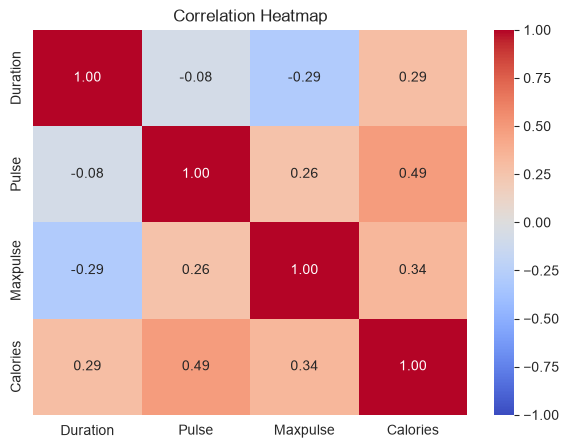

In [41]:
plt.figure(figsize=(7, 5))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Heatmap")
plt.show()

Correlation of Each Column with Calories

In [42]:
calories_corr = corr_matrix["Calories"].drop("Calories").sort_values(ascending=False)
print("Correlation with Calories:")
print(calories_corr.round(3))

Correlation with Calories:
Pulse       0.491
Maxpulse    0.337
Duration    0.292
Name: Calories, dtype: float64


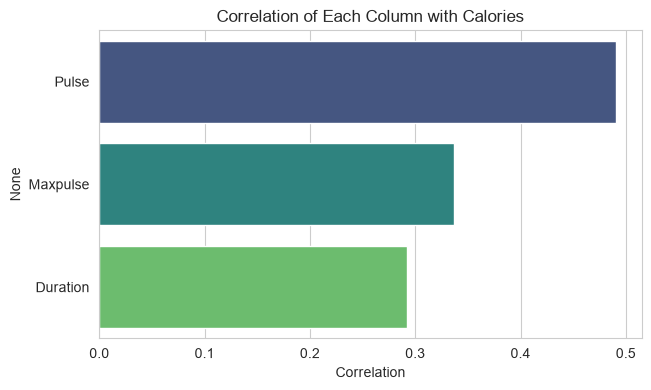

In [43]:
plt.figure(figsize=(7, 4))
sns.barplot(x=calories_corr.values, y=calories_corr.index, palette="viridis")
plt.title("Correlation of Each Column with Calories")
plt.xlabel("Correlation")
plt.show()

Scatter Plots of Strong and Weak Relationships

A scatter plot shows the relationship directly. The strongest pair in this data, Pulse and Calories, is compared with a pair that has almost no relationship, Duration and Pulse.

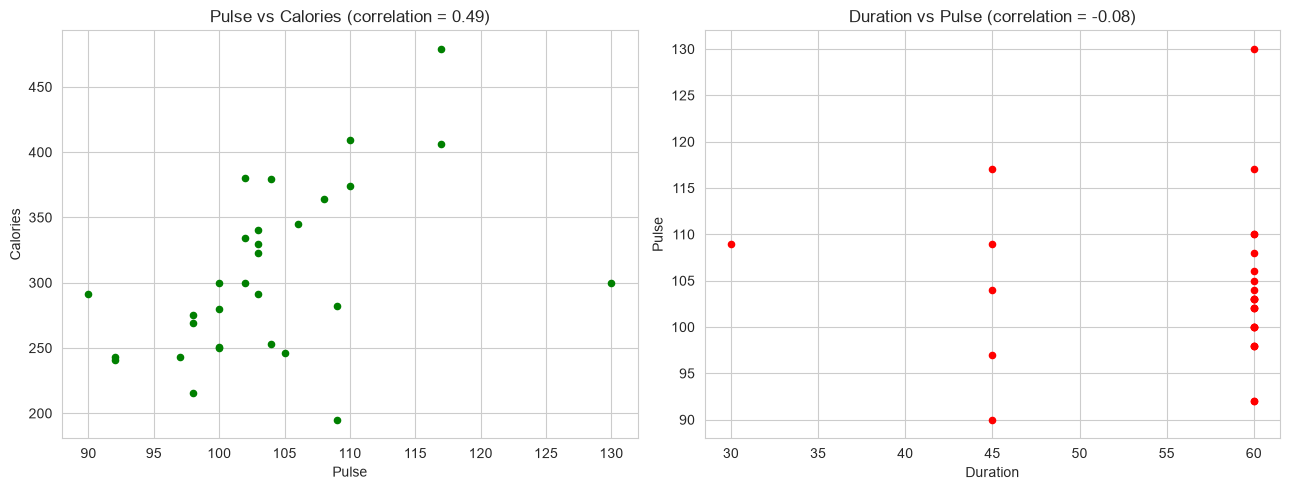

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

df.plot(kind="scatter", x="Pulse", y="Calories", ax=axes[0], color="green")
axes[0].set_title("Pulse vs Calories (correlation = %.2f)" % df["Pulse"].corr(df["Calories"]))

df.plot(kind="scatter", x="Duration", y="Pulse", ax=axes[1], color="red")
axes[1].set_title("Duration vs Pulse (correlation = %.2f)" % df["Duration"].corr(df["Pulse"]))

plt.tight_layout()
plt.show()

Correlation Between Two Specific Columns

The corr() method can also be used on one column against another.

In [45]:
print("Pulse and Calories     :", round(df["Pulse"].corr(df["Calories"]), 3))
print("Maxpulse and Calories  :", round(df["Maxpulse"].corr(df["Calories"]), 3))
print("Duration and Calories  :", round(df["Duration"].corr(df["Calories"]), 3))
print("Pulse and Maxpulse     :", round(df["Pulse"].corr(df["Maxpulse"]), 3))

Pulse and Calories     : 0.491
Maxpulse and Calories  : 0.337
Duration and Calories  : 0.292
Pulse and Maxpulse     : 0.261


Finding the Strongest and Weakest Pairs

In [46]:
pairs = corr_matrix.unstack().reset_index()
pairs.columns = ["Column 1", "Column 2", "Correlation"]

# keep each pair once and remove a column paired with itself
pairs = pairs[pairs["Column 1"] < pairs["Column 2"]]
pairs["Strength"] = pairs["Correlation"].abs()
pairs = pairs.sort_values(by="Strength", ascending=False).drop(columns="Strength")
pairs.round(3).reset_index(drop=True)

,Column 1,Column 2,Correlation
0,Calories,Pulse,0.491
1,Calories,Maxpulse,0.337
2,Calories,Duration,0.292
3,Duration,Maxpulse,-0.291
4,Maxpulse,Pulse,0.261
5,Duration,Pulse,-0.075


Effect of Wrong Data on Correlation

To see why data cleaning matters, the correlation of Duration and Calories is calculated on the raw data, where Duration contains the wrong value 450, and on the cleaned data.

In [47]:
raw_corr = df_raw["Duration"].corr(df_raw["Calories"])
clean_corr = df["Duration"].corr(df["Calories"])

print("Correlation of Duration and Calories on raw data    :", round(raw_corr, 3))
print("Correlation of Duration and Calories on cleaned data:", round(clean_corr, 3))

Correlation of Duration and Calories on raw data    : -0.121
Correlation of Duration and Calories on cleaned data: 0.292


Observations

Pulse has the strongest relationship with Calories (about 0.49), which is a moderate positive correlation: workouts with a higher average heart rate burned more calories.

Maxpulse (about 0.34) and Duration (about 0.29) have a weaker positive relationship with Calories.

Duration and Pulse have almost no relationship (about -0.08), and Duration and Maxpulse have a weak negative one (about -0.29). In this dataset most workouts last exactly 60 minutes, so Duration varies very little, which limits how much it can show.

The correlation of Duration and Calories changes from about -0.12 on the raw data to about 0.29 on the cleaned data. The wrong Duration value of 450 hid the relationship, which shows that data should be cleaned before correlation is calculated.

A correlation shows that two columns move together but it does not prove that one causes the other. The dataset is also small, with only 30 rows, so the values should be treated as indications and not as final facts.

Conclusion of Assignment 48

The corr() method was used to measure the relationship between the numeric columns of the fitness dataset. The correlation matrix, heatmap, bar chart and scatter plots were used to read the results. Pulse was the column most related to Calories, followed by Maxpulse and Duration, and none of the relationships was very strong. Comparing the raw and cleaned data showed that one wrong value can change a correlation completely, so cleaning improves the reliability of the results.

Overall Summary

Assignment 46: The structure and statistics of the dataset were explored with head(), tail(), info(), describe(), filtering, sorting and groupby().
Assignment 47: Empty cells, wrong date formats, wrong values and duplicate rows were cleaned.
Assignment 48: Relationships between the columns were measured and visualised with corr() and heatmaps.